# 10 Model comparison on G0–G3

All six models side by side, read from `results/log.csv` (validation rows of the G0–G3 runs from notebooks 04 to
09). A cell is shown only when its model has been validated with all of seeds 0, 1 and 2 on that set; the first
table lists what is still missing. Nothing is refitted here.

Sections 3 and 4 split the scores into **known** and **unknown** customers (a `uid` already seen in the data the
model was trained on, or not), using the scores saved in `results/preds/`. The split uses only information available
when a transaction arrives, so it can also be used to weight models in an ensemble without leakage.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve

from src import experiment, feature_sets as fs, segments
from src.metrics import top_rows
from src.split import holdout_indices

MODELS = ["logreg", "rf", "lgbm", "xgboost", "catboost", "mlp"]
LABELS = {"logreg": "Logistic regression", "rf": "Random forest", "lgbm": "LightGBM",
          "xgboost": "XGBoost", "catboost": "CatBoost", "mlp": "MLP"}
FEATURE_SETS = list(fs.FEATURE_SETS)
SEEDS = [0, 1, 2]
IMPORTANCE_DIR = ROOT / "results" / "importance"    # written by section 6 of notebooks 04 to 09
METRICS = {"pr_auc": "PR-AUC", "auroc": "AUROC", "recall_top1pct": "recall in top 1%",
           "precision_top1pct": "precision in top 1%", "precision": "precision at threshold",
           "recall": "recall at threshold"}
pd.set_option("display.width", 160)

## 1. What has been run

In [2]:
spec = fs.load_spec()
ids = pd.read_parquet(ROOT / spec["parquet"],
                      columns=["TransactionID", "TransactionDT", "TransactionDay", "uid", "isFraud"])
train_idx, val_idx, _ = holdout_indices(ids)
ids = ids.iloc[:val_idx[-1] + 1]                       # the test block is not used
sizes = experiment.block_sizes(ids, train_idx, val_idx)
n_val, fraud_val = sizes["val"]

# current_runs leaves out early-stopping runs from the older setup (1,500-tree cap, no refit); see src/experiment.py
log = experiment.current_runs(pd.read_csv(experiment.LOG_PATH))
val = log[(log["split"] == "val") & log["model"].isin(MODELS) & log["feature_set"].isin(FEATURE_SETS)].copy()

def settings(p):
    d = json.loads(p)
    return json.dumps({k: v for k, v in d.items() if k not in experiment.NOT_SETTINGS}, sort_keys=True)

val["settings"] = val["params"].map(settings)
# precision in the top 1%, derived from the logged recall: recall x fraud rows / rows flagged
val["precision_top1pct"] = val["recall_top1pct"] * fraud_val / top_rows(n_val)
status, rows = {}, []
for m in MODELS:
    for g in FEATURE_SETS:
        cell = val[(val["model"] == m) & (val["feature_set"] == g)]
        complete = [s for s, part in cell.groupby("settings") if sorted(part["seed"]) == SEEDS]
        if len(complete) > 1:
            raise ValueError(f"{m}/{g}: more than one set of settings validated with all seeds; "
                             "keep one in the log or choose explicitly")
        status[(m, g)] = "done" if complete else (f"seeds {sorted(cell['seed'])}" if len(cell) else "not run")
        if complete:
            rows.append(cell[cell["settings"] == complete[0]])
done = pd.concat(rows) if rows else val.iloc[:0]
pd.Series(status).unstack().reindex(index=MODELS, columns=FEATURE_SETS).rename(index=LABELS)

,G0,G1,G2,G3
Logistic regression,done,done,done,done
Random forest,done,done,done,done
LightGBM,done,done,done,done
XGBoost,done,done,done,done
CatBoost,done,done,done,done
MLP,done,done,done,done


## 2. Validation results (mean ± sample sd over seeds 0, 1, 2)

Precision in the top 1% is derived from the logged recall in the top 1% and ranks models the same way; recall in the top
1% is capped well below 1 (printed below). Precision and recall at the threshold use the F1-best threshold picked on
the validation block itself, so they are slightly optimistic.

In [3]:
def table(metric):
    g = done.groupby(["model", "feature_set"])[metric]
    cell = g.mean().map("{:.4f}".format) + " ± " + g.std().map("{:.4f}".format)
    return cell.unstack().reindex(index=MODELS, columns=FEATURE_SETS).rename(index=LABELS)

print(f"Validation block: {fraud_val:,} fraud in {n_val:,} rows; the top 1% is {top_rows(n_val):,} rows, "
      f"so recall in the top 1% is at most {top_rows(n_val) / fraud_val:.3f}.")
for metric, label in METRICS.items():
    print(label)
    display(table(metric))

Validation block: 1,851 fraud in 59,054 rows; the top 1% is 591 rows, so recall in the top 1% is at most 0.319.
PR-AUC


feature_set,G0,G1,G2,G3
model,,,,
Logistic regression,0.3395 ± 0.0000,0.3521 ± 0.0000,0.3506 ± 0.0000,0.3525 ± 0.0000
Random forest,0.5411 ± 0.0021,0.5607 ± 0.0016,0.5667 ± 0.0015,0.5620 ± 0.0006
LightGBM,0.6076 ± 0.0037,0.6221 ± 0.0042,0.6238 ± 0.0009,0.6240 ± 0.0058
XGBoost,0.6057 ± 0.0302,0.6495 ± 0.0025,0.6449 ± 0.0023,0.6434 ± 0.0032
CatBoost,0.5498 ± 0.0045,0.5625 ± 0.0024,0.5504 ± 0.0023,0.5485 ± 0.0026
MLP,0.4237 ± 0.0146,0.4404 ± 0.0042,0.4360 ± 0.0041,0.4379 ± 0.0081


AUROC


feature_set,G0,G1,G2,G3
model,,,,
Logistic regression,0.8326 ± 0.0000,0.8399 ± 0.0000,0.8386 ± 0.0000,0.8401 ± 0.0000
Random forest,0.9139 ± 0.0003,0.9216 ± 0.0007,0.9237 ± 0.0007,0.9228 ± 0.0012
LightGBM,0.9234 ± 0.0006,0.9281 ± 0.0012,0.9267 ± 0.0011,0.9273 ± 0.0005
XGBoost,0.9174 ± 0.0072,0.9246 ± 0.0013,0.9239 ± 0.0009,0.9242 ± 0.0004
CatBoost,0.9040 ± 0.0009,0.9077 ± 0.0008,0.9068 ± 0.0007,0.9059 ± 0.0023
MLP,0.8500 ± 0.0028,0.8614 ± 0.0025,0.8603 ± 0.0047,0.8607 ± 0.0030


recall in top 1%


feature_set,G0,G1,G2,G3
model,,,,
Logistic regression,0.2075 ± 0.0000,0.2102 ± 0.0000,0.2091 ± 0.0000,0.2112 ± 0.0000
Random forest,0.2699 ± 0.0011,0.2728 ± 0.0014,0.2703 ± 0.0003,0.2694 ± 0.0008
LightGBM,0.2901 ± 0.0030,0.2952 ± 0.0008,0.2941 ± 0.0003,0.2934 ± 0.0005
XGBoost,0.2932 ± 0.0064,0.3022 ± 0.0003,0.3002 ± 0.0006,0.2995 ± 0.0003
CatBoost,0.2871 ± 0.0030,0.2905 ± 0.0011,0.2847 ± 0.0009,0.2860 ± 0.0019
MLP,0.2478 ± 0.0060,0.2545 ± 0.0034,0.2494 ± 0.0038,0.2530 ± 0.0027


... (2 outputs left out)

precision at threshold


feature_set,G0,G1,G2,G3
model,,,,
Logistic regression,0.4131 ± 0.0000,0.4168 ± 0.0000,0.4180 ± 0.0000,0.4893 ± 0.0000
Random forest,0.5362 ± 0.0307,0.5785 ± 0.0419,0.5808 ± 0.0168,0.5995 ± 0.0243
LightGBM,0.6662 ± 0.0322,0.6836 ± 0.0119,0.7334 ± 0.0107,0.7172 ± 0.0067
XGBoost,0.7105 ± 0.0207,0.7198 ± 0.0067,0.7367 ± 0.0039,0.7263 ± 0.0408
CatBoost,0.6907 ± 0.0286,0.6593 ± 0.0236,0.6341 ± 0.0335,0.5916 ± 0.0314
MLP,0.5483 ± 0.0254,0.5789 ± 0.0517,0.5768 ± 0.0112,0.5244 ± 0.0586


recall at threshold


feature_set,G0,G1,G2,G3
model,,,,
Logistic regression,0.3160 ± 0.0000,0.3355 ± 0.0000,0.3279 ± 0.0000,0.2966 ± 0.0000
Random forest,0.4986 ± 0.0296,0.5141 ± 0.0361,0.5365 ± 0.0124,0.5118 ± 0.0168
LightGBM,0.5318 ± 0.0153,0.5419 ± 0.0052,0.5186 ± 0.0092,0.5224 ± 0.0083
XGBoost,0.5134 ± 0.0399,0.5601 ± 0.0017,0.5527 ± 0.0025,0.5487 ± 0.0242
CatBoost,0.4362 ± 0.0085,0.4677 ± 0.0095,0.4747 ± 0.0159,0.4925 ± 0.0168
MLP,0.3612 ± 0.0354,0.3657 ± 0.0256,0.3551 ± 0.0041,0.3848 ± 0.0332


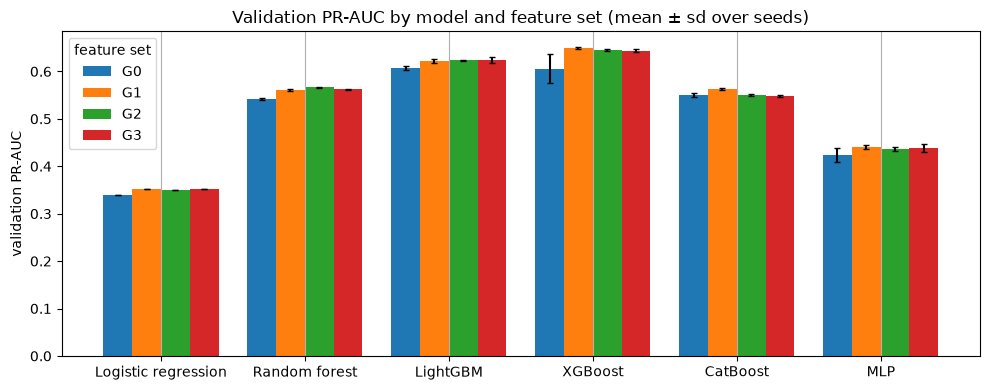

In [4]:
mean = done.groupby(["model", "feature_set"])["pr_auc"].mean().unstack().reindex(index=MODELS, columns=FEATURE_SETS)
sd = done.groupby(["model", "feature_set"])["pr_auc"].std().unstack().reindex(index=MODELS, columns=FEATURE_SETS)
fig, ax = plt.subplots(figsize=(10, 4))
width = 0.8 / len(FEATURE_SETS)
x = np.arange(len(MODELS))
for i, g in enumerate(FEATURE_SETS):
    ax.bar(x + i * width, mean[g], width, yerr=sd[g].fillna(0), capsize=2, label=g)
ax.set_xticks(x + width * (len(FEATURE_SETS) - 1) / 2, [LABELS[m] for m in MODELS])
ax.set_ylabel("validation PR-AUC")
ax.set_title("Validation PR-AUC by model and feature set (mean ± sd over seeds)")
ax.legend(title="feature set")
ax.grid(axis="x")
fig.tight_layout()
plt.show()

**What each feature group adds:** the change in mean validation PR-AUC from one set to the next, per model.

In [5]:
gain = mean.diff(axis=1).iloc[:, 1:]
gain.columns = [f"{a} → {b}" for a, b in zip(FEATURE_SETS[:-1], FEATURE_SETS[1:])]
gain["G0 → G3"] = mean["G3"] - mean["G0"]
gain.rename(index=LABELS).round(4)

,G0 → G1,G1 → G2,G2 → G3,G0 → G3
model,,,,
Logistic regression,0.0126,-0.0016,0.0020,0.0130
Random forest,0.0196,0.0060,-0.0046,0.0210
LightGBM,0.0144,0.0017,0.0002,0.0164
XGBoost,0.0437,-0.0046,-0.0014,0.0377
CatBoost,0.0128,-0.0122,-0.0019,-0.0013
MLP,0.0166,-0.0044,0.0019,0.0142


**Precision–recall curves** of every model on the largest feature set with results (seed 0, validation block). The
dashed line is a model with no skill.

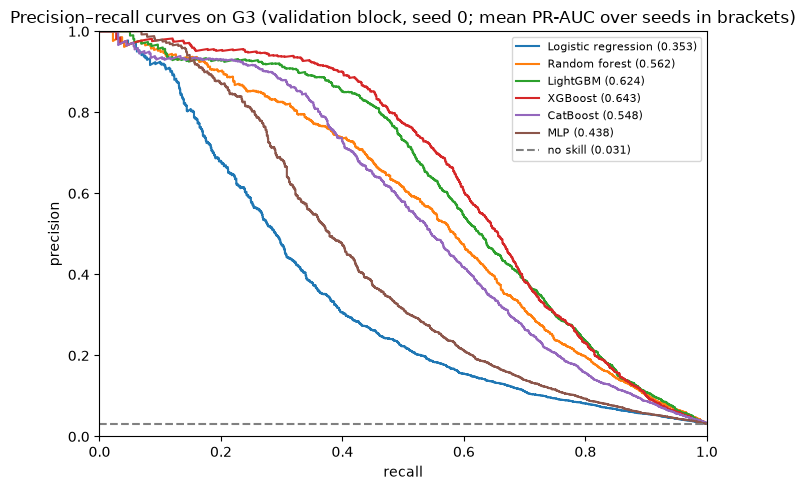

In [6]:
done_sets = [g for g in FEATURE_SETS if any(status[(m, g)] == "done" for m in MODELS)]
if done_sets:
    g = done_sets[-1]
    fig, ax = plt.subplots(figsize=(7, 5))
    for m in MODELS:
        path = experiment.PREDS_DIR / f"{m}_{g}_val_seed0.parquet"
        if status[(m, g)] == "done" and path.exists():
            p = pd.read_parquet(path)
            precision, recall, _ = precision_recall_curve(p["isFraud"], p["score"])
            ax.plot(recall, precision, lw=1.5, label=f"{LABELS[m]} ({mean.loc[m, g]:.3f})")
    ax.axhline(fraud_val / n_val, ls="--", color="grey", label=f"no skill ({fraud_val / n_val:.3f})")
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(f"Precision–recall curves on {g} (validation block, seed 0; mean PR-AUC over seeds in brackets)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

## 3. Known vs unknown customers (validation block)

A validation row is **known** if its `uid` appears in the training block, otherwise **unknown**
(`src/segments.py`). History features (G2, G3) can only help known customers, so comparing the two segments shows
where the customer profile pays off, and whether different models are best for different segments, which is the
case for an ensemble. PR-AUC is the mean over seeds 0, 1, 2; the interval is a 95% bootstrap interval over rows
(`N_BOOT` resamples). Overlapping intervals mean the gap between two models may be noise.

In [7]:
known_by_id = pd.Series(segments.known_uid(ids["uid"], set(ids["uid"].iloc[train_idx])),
                        index=ids["TransactionID"].to_numpy())
print(f"validation rows: known {known_by_id.iloc[val_idx].mean():.1%}, "
      f"unknown {1 - known_by_id.iloc[val_idx].mean():.1%}")

N_BOOT = 200
rows = []
for m in MODELS:
    for g in FEATURE_SETS:
        paths = [experiment.PREDS_DIR / f"{m}_{g}_val_seed{s}.parquet" for s in SEEDS]
        if status[(m, g)] != "done" or not all(p.exists() for p in paths):
            continue
        preds = [pd.read_parquet(p) for p in paths]
        if not all(p["TransactionID"].equals(preds[0]["TransactionID"]) for p in preds):
            raise ValueError(f"{m}/{g}: saved validation scores cover different rows")
        known = known_by_id.reindex(preds[0]["TransactionID"]).to_numpy()
        t = segments.segment_pr_auc(preds[0]["isFraud"].to_numpy(), [p["score"].to_numpy() for p in preds],
                                    known, n_boot=N_BOOT)
        rows.append(t.assign(model=m, feature_set=g))
by_segment = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

if len(by_segment):
    display(by_segment.groupby("segment")[["rows", "fraud"]].first())
    text = (by_segment["pr_auc"].map("{:.4f}".format) + " [" + by_segment["low"].map("{:.3f}".format)
            + ", " + by_segment["high"].map("{:.3f}".format) + "]")
    table_seg = (by_segment.assign(text=text).pivot(index="model", columns=["segment", "feature_set"], values="text")
                 .reindex([m for m in MODELS if m in set(by_segment["model"])]).rename(index=LABELS))
    display(table_seg)
else:
    print("No complete validation scores saved yet: run notebooks 04 to 09 first.")

validation rows: known 48.6%, unknown 51.4%


,rows,fraud
segment,,
known,28685,640
unknown,30369,1211


segment,known,unknown,known,unknown,known,unknown,known,unknown
feature_set,G0,G0,G1,G1,G2,G2,G3,G3
model,,,,,,,,
Logistic regression,"0.2842 [0.249, 0.319]","0.3677 [0.341, 0.398]","0.2780 [0.244, 0.316]","0.3895 [0.363, 0.419]","0.2789 [0.245, 0.318]","0.3867 [0.362, 0.416]","0.2795 [0.245, 0.318]","0.3901 [0.364, 0.419]"
Random forest,"0.6611 [0.627, 0.699]","0.5266 [0.498, 0.560]","0.7119 [0.679, 0.749]","0.5237 [0.498, 0.558]","0.7288 [0.697, 0.764]","0.5209 [0.494, 0.555]","0.7211 [0.689, 0.756]","0.5201 [0.493, 0.554]"
LightGBM,"0.7539 [0.721, 0.786]","0.5477 [0.523, 0.578]","0.7831 [0.750, 0.815]","0.5508 [0.526, 0.582]","0.7952 [0.762, 0.825]","0.5467 [0.524, 0.578]","0.7992 [0.768, 0.830]","0.5466 [0.523, 0.579]"
XGBoost,"0.8040 [0.771, 0.834]","0.5175 [0.492, 0.547]","0.8427 [0.811, 0.871]","0.5427 [0.519, 0.575]","0.8445 [0.815, 0.872]","0.5348 [0.513, 0.565]","0.8414 [0.811, 0.869]","0.5369 [0.515, 0.568]"
CatBoost,"0.5726 [0.535, 0.611]","0.5512 [0.526, 0.579]","0.6034 [0.565, 0.638]","0.5519 [0.527, 0.582]","0.5919 [0.555, 0.625]","0.5404 [0.516, 0.571]","0.5912 [0.553, 0.623]","0.5397 [0.514, 0.570]"
MLP,"0.3563 [0.320, 0.393]","0.4602 [0.435, 0.492]","0.3796 [0.342, 0.415]","0.4757 [0.450, 0.507]","0.3924 [0.353, 0.429]","0.4639 [0.440, 0.498]","0.3940 [0.353, 0.426]","0.4661 [0.440, 0.498]"


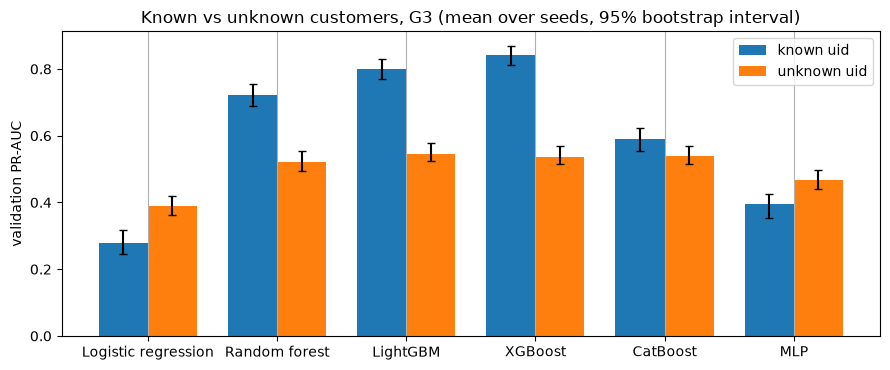

In [8]:
if len(by_segment):
    g = [g for g in FEATURE_SETS if g in set(by_segment["feature_set"])][-1]   # the largest set with results
    t = by_segment[by_segment["feature_set"] == g]
    models = [m for m in MODELS if m in set(t["model"])]
    fig, ax = plt.subplots(figsize=(9, 3.8))
    x = np.arange(len(models))
    for i, seg in enumerate(segments.SEGMENTS):
        part = t[t["segment"] == seg].set_index("model").loc[models]
        err = np.vstack([part["pr_auc"] - part["low"], part["high"] - part["pr_auc"]])
        ax.bar(x + (i - 0.5) * 0.38, part["pr_auc"], 0.38, yerr=err, capsize=3, label=f"{seg} uid")
    ax.set_xticks(x, [LABELS[m] for m in models])
    ax.set_ylabel("validation PR-AUC")
    ax.set_title(f"Known vs unknown customers, {g} (mean over seeds, 95% bootstrap interval)")
    ax.legend()
    ax.grid(axis="x")
    fig.tight_layout()
    plt.show()

## 4. Known vs unknown on the time-CV fold scores (for an ensemble)

To choose ensemble weights without using the validation block, use the fold scores saved by the model notebooks
(`SAVE_OOF`). Within each fold, **known** means the `uid` appears in that fold's training months
(`segments.fold_reference_uids`), matching what the model saw. PR-AUC is computed per fold and averaged over the
4 folds. The validation block (section 3) then checks whatever is chosen here.

In [9]:
fold_ref = segments.fold_reference_uids(ids, train_idx)
uid_by_id = pd.Series(ids["uid"].to_numpy(), index=ids["TransactionID"].to_numpy())
rows = []
for m in MODELS:
    for g in FEATURE_SETS:
        path = experiment.PREDS_DIR / f"{m}_{g}_oof_seed0.parquet"
        if not path.exists():
            continue
        oof = pd.read_parquet(path)
        uid = uid_by_id.reindex(oof["TransactionID"]).to_numpy()
        known = np.array([u in fold_ref[k] for u, k in zip(uid, oof["fold"])])
        for k, part in oof.groupby("fold"):
            mask = (oof["fold"] == k).to_numpy()
            t = segments.segment_pr_auc(part["isFraud"].to_numpy(), part["score"].to_numpy(), known[mask], n_boot=0)
            rows.append(t.assign(model=m, feature_set=g, fold=k))
oof_segment = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
if len(oof_segment):
    print("Mean PR-AUC over the 4 folds; known share of fold-validation rows:",
          f"{oof_segment.groupby('segment')['rows'].sum()['known'] / oof_segment['rows'].sum():.1%}")
    display(oof_segment.groupby(["model", "segment", "feature_set"])["pr_auc"].mean().unstack(["segment", "feature_set"])
            .reindex([m for m in MODELS if m in set(oof_segment["model"])]).rename(index=LABELS).round(4))
else:
    print("No fold scores saved yet: run notebooks 04 to 09 with SAVE_OOF = True.")

Mean PR-AUC over the 4 folds; known share of fold-validation rows: 40.0%


segment               known                         unknown                        
feature_set              G0      G1      G2      G3      G0      G1      G2      G3
model                                                                              
Logistic regression  0.2327  0.2316  0.2331  0.2380  0.4552  0.4587  0.4631  0.4650
Random forest        0.5691  0.6285  0.6447  0.6293  0.5878  0.5832  0.5857  0.5850
LightGBM             0.6449  0.7271  0.7410  0.7186  0.6085  0.6154  0.6171  0.6163
XGBoost              0.7060  0.7300  0.7634  0.7835  0.5724  0.5895  0.5920  0.5983
CatBoost             0.4889  0.5116  0.5078  0.4995  0.6166  0.6256  0.6242  0.6223
MLP                  0.3507  0.3764  0.3509  0.3572  0.5181  0.5313  0.5373  0.5207

## 5. Feature importance across models

Permutation importance (drop in validation PR-AUC when a column is shuffled) from section 6 of each model notebook,
read from `results/importance/`. It is the same measure for every model, so the ranks can be compared. Shown: the
20 inputs with the best average rank across the models that have results.

In [10]:
files = sorted(IMPORTANCE_DIR.glob("*.csv"))
if files:
    imp = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    imp["rank"] = imp.groupby(["model", "feature_set"])["pr_auc_drop"].rank(ascending=False)
    for g, part in imp.groupby("feature_set"):
        ranks = part.pivot(index="feature", columns="model", values="rank")
        ranks = ranks[[m for m in MODELS if m in ranks.columns]].rename(columns=LABELS)
        group = part.drop_duplicates("feature").set_index("feature")["group"]
        table = ranks.assign(mean_rank=ranks.mean(axis=1), group=group).sort_values("mean_rank").head(20)
        print(f"{g}: rank of each input by permutation importance (1 = most important)")
        display(table.round(1))
        by_group = (part.groupby(["group", "model"])["pr_auc_drop"].sum().unstack()
                    .reindex(columns=[m for m in MODELS if m in set(part["model"])]).rename(columns=LABELS))
        print(f"{g}: total PR-AUC drop by feature group")
        display(by_group.round(4))
else:
    print("No importance tables yet: run section 6 of notebooks 04 to 09.")

G3: rank of each input by permutation importance (1 = most important)


model,Logistic regression,Random forest,LightGBM,XGBoost,CatBoost,MLP,mean_rank,group
feature,,,,,,,,
fe_D1n,1.0,6.0,5.0,5.0,9.0,3.0,4.8,G1_row_level
C11,4.0,2.0,12.0,14.0,6.0,17.0,9.2,G0_raw
C14,2.0,5.0,7.0,12.0,5.0,40.0,11.8,G0_raw
C1,16.0,1.0,1.0,1.0,1.0,61.0,13.5,G0_raw
fe_amt_log,13.0,20.0,53.0,35.0,16.0,2.0,23.2,G1_row_level
C2,68.0,3.0,11.0,13.0,7.0,37.0,23.2,G0_raw
addr1,45.0,11.0,10.0,6.0,13.0,66.0,25.2,G0_raw
fe_card4_card6,49.0,37.0,14.0,18.0,22.0,33.0,28.8,G1_row_level
V283,40.0,8.0,52.0,45.0,27.0,7.0,29.8,G0_raw


G3: total PR-AUC drop by feature group


model,Logistic regression,Random forest,LightGBM,XGBoost,CatBoost,MLP
group,,,,,,
G0_raw,1.1696,0.4051,0.5159,0.4515,0.4715,0.4814
G1_row_level,0.3823,0.0668,0.1273,0.1347,0.0543,0.0850
G2_card_device_history,0.0420,0.0476,0.0643,0.0751,0.0289,0.0134
G3_customer_history,0.0077,0.0107,0.0140,0.0171,0.0096,0.0097


## 6. Findings

All 24 cells are done (section 1). Numbers are validation PR-AUC, mean over seeds 0, 1, 2, unless stated.

- **Best model and set (RQ2).** XGBoost on G1 scores highest, 0.6495 ± 0.0025. The best other model is LightGBM,
  0.6240 on G3, so the margin is 0.0255. On G3 alone the order is XGBoost 0.6434, LightGBM 0.6240, random forest
  0.5620, CatBoost 0.5485, MLP 0.4379, logistic regression 0.3525. XGBoost also leads on recall in the top 1% (0.3022
  on G1, against a ceiling of 0.319), while LightGBM has the highest AUROC (0.9281 on G1), so the top two swap places
  under AUROC; PR-AUC is the primary metric.
- **Model choice matters far more than features (RQ3).** On G3 the spread between the best and worst model is
  0.2909 (0.6434 − 0.3525), and between the best tree model and random forest it is 0.0814. The largest gain from
  adding all engineered features, G0 → G3, is 0.0377 (XGBoost); for the others it is 0.0130 to 0.0210, and CatBoost
  loses 0.0013. Nearly all of that gain is the row-level step G0 → G1, which helps every model (+0.0126 to +0.0437).
  The customer-profile step G2 → G3 changes PR-AUC by −0.0046 to +0.0020, within the spread between seeds, so
  customer history adds nothing measurable for any model. The card and device step G1 → G2 helps only random forest
  (+0.0060) and LightGBM (+0.0017).
- **Known vs unknown customers (section 3).** 48.6% of validation rows are from known customers, but only 640 of the
  1,851 fraud cases. The four tree models score known customers far higher than unknown ones (XGBoost 0.8414 vs
  0.5369 on G3, LightGBM 0.7992 vs 0.5466, random forest 0.7211 vs 0.5201), with CatBoost the exception among them
  (0.5912 vs 0.5397). Logistic regression and the MLP do the reverse: known 0.2795 and 0.3940, unknown 0.3901 and
  0.4661. Nearly all of the difference between the tree models is on known customers; on unknown customers
  LightGBM, CatBoost and XGBoost are within 0.010 of each other (0.5466, 0.5397, 0.5369), with overlapping intervals.
- **Is a different model best for each segment?** Not clearly on validation. XGBoost is best on known customers
  (0.8414 [0.811, 0.869]) but its interval overlaps LightGBM's (0.7992 [0.768, 0.830]); on unknown customers
  LightGBM is highest (0.5466 [0.523, 0.579]) but overlaps CatBoost, XGBoost and random forest. The fold scores
  (section 4) point the same way more strongly: on G3, XGBoost is best on known customers (0.7835) and CatBoost on
  unknown ones (0.6223, against 0.5983 for XGBoost). An ensemble weighted by segment, with weights chosen on the
  fold scores, is therefore worth trying, but the validation intervals give no guarantee it beats XGBoost alone.
- **Inputs every model relies on (section 5).** The normalised D1 feature `fe_D1n` (G1) has the best average rank
  (4.8): first for logistic regression and in the top 10 for every model. C1 is first for random forest, LightGBM,
  XGBoost and CatBoost, but 16th for logistic regression and 61st for the MLP; the C counts (C11, C14, C2) and card1
  frequency fill most of the rest. By group, G0 carries the largest total drop for every model, then G1; G3's total
  is the smallest for every model (0.0077 to 0.0171), which matches the G2 → G3 result above.
- **Caveats.** Precision and recall at the threshold use an F1-best threshold chosen on the validation block, so they
  are optimistic; the test block will be scored once with the stored thresholds (Step 19). Seed spread only covers
  model randomness, not variation between time periods. 6 of 12 XGBoost and 7 of 12 CatBoost validation fits stopped
  near the 3,000-tree cap (see `07_xgboost` and `08_catboost`).